# 02 · Segmentation backends

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/james-kidd/pbn-gradio/blob/claude/notebook-demos/demos/notebooks/02_segmentation_backends.ipynb)

**SLIC, Felzenszwalb and watershed are segmenters** — image in, regions
out. They are alternatives to one another.

**RAG merging is not one of them.** It takes regions and returns fewer
regions, so it composes with *any* backend.

Conflating the two had a visible consequence in the original code, shown
partway down this notebook.

In [1]:
# Bootstrap: clones what it needs in Colab, finds what exists locally.
import pathlib, subprocess, sys

REPO = "https://github.com/james-kidd/pbn-gradio.git"
BRANCH = "claude/notebook-demos"

def _demos_root():
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / "nbtools" / "bootstrap.py").exists():
            return base
    dest = (pathlib.Path("/content/pbn-gradio") if pathlib.Path("/content").is_dir()
            else pathlib.Path.cwd() / "pbn-gradio")
    if not (dest / "demos" / "nbtools").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--quiet",
                        "--branch", BRANCH, REPO, str(dest)], check=True)
    return dest / "demos"

sys.path.insert(0, str(_demos_root()))
from nbtools.bootstrap import setup

tk = setup()                           # installs anything missing, first
from nbtools import scenes, display    # these need cv2/matplotlib, so: after

toolkit   /home/user/pbn-gradio  (found locally)
modules   geo, land_use, optimize, pipeline, segmenters, siting, topology
gradio    stubbed (UI layer not needed for these demos)


In [2]:
image = scenes.simple_farm()
working = tk.pipeline.load_and_resize(image, 800)
lab = tk.pipeline.preprocess_rgb(working)
MIN_AREA = int(working.shape[0] * working.shape[1] * 0.001)
print(f"working {working.shape[1]}x{working.shape[0]}, min region {MIN_AREA}px")

working 800x600, min region 480px


## Each backend assumes something different about what a region *is*

That assumption is the whole basis for choosing between them:

| Backend | Assumes a region is… | Best for | Weakness |
|---|---|---|---|
| `slic` | compact and similarly sized | paint-by-number, where uniformity **is** the goal | fights thin and elongated features |
| `felzenszwalb` | whatever shape real boundaries make | land parcels | cannot target an exact region count |
| `watershed` | a catchment basin of the gradient | strongest boundary adherence | needs good markers |
| `precomputed` | already known, supplied externally | **real cadastral parcels** | requires that layer to exist |

slic           slic → merge<8 → drop<480px → fill-gaps (22 regions)


felzenszwalb   felzenszwalb → merge<8 → drop<480px → fill-gaps (9 regions)


watershed      watershed → merge<8 → drop<480px → fill-gaps (44 regions)


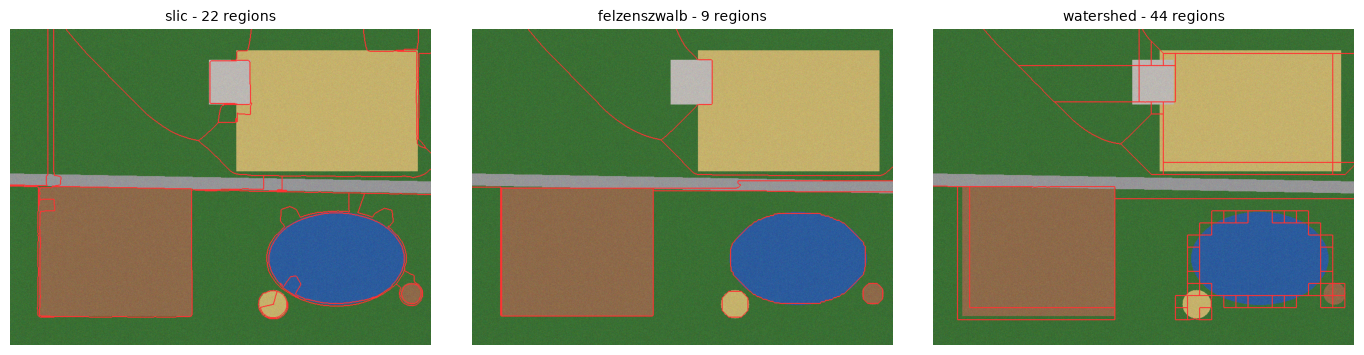

In [3]:
variants, titles = [], []
for backend in tk.segmenters.INTERCHANGEABLE:
    r = tk.segmenters.segment(
        lab, backend, merge_threshold=8.0, min_area=MIN_AREA, fill=True,
        n_segments=900, compactness=10.0, sigma=2.0,
    )
    variants.append(tk.pipeline.render_segmentation_overlay(working, r.labels))
    titles.append(f"{backend} - {r.n_regions} regions")
    print(f"{backend:14s} {r.describe()}")

display.grid(variants, titles, columns=3, width=14)

## Merging composes with every backend

The same post-process, applied after each of them. Note how differently
each responds: SLIC deliberately over-segments and collapses hard, while
Felzenszwalb starts closer to the target.

In [4]:
rows = []
for backend in tk.segmenters.INTERCHANGEABLE:
    counts = {}
    for thresh in (None, 4.0, 8.0, 14.0):
        r = tk.segmenters.segment(
            lab, backend, merge_threshold=thresh, min_area=MIN_AREA,
            n_segments=900, compactness=10.0, sigma=2.0,
        )
        counts[thresh] = r.n_regions
    rows.append([backend, counts[None], counts[4.0], counts[8.0], counts[14.0]])

display.table(rows, ["Backend", "no merge", "merge@4", "merge@8", "merge@14"])

| Backend | no merge | merge@4 | merge@8 | merge@14 |
|---|---|---|---|---|
| slic | 771 | 44 | 22 | 11 |
| felzenszwalb | 269 | 13 | 9 | 8 |
| watershed | 884 | 59 | 44 | 24 |

### The bug this structure fixed

The original `segment_image` bundled RAG merging into the SLIC branch
only. Selecting Felzenszwalb left the "RAG Merge Threshold" slider wired
to nothing — a control that lies.

The `felzenszwalb` row above is the fix: its counts change with the
threshold, as they always should have.

## The backend that matters once real data arrives

`precomputed` does not segment at all. A municipal cadastre **is** the
segmentation, and it is authoritative in a way no image-derived guess can
be.

Everything downstream consumes a label array and does not care where it
came from, so attaching real parcel data is a backend swap rather than a
rewrite. Here a fake "parcel layer" stands in for the rasterised vector
layer you would really pass.

precomputed → no post-processing (9 regions)


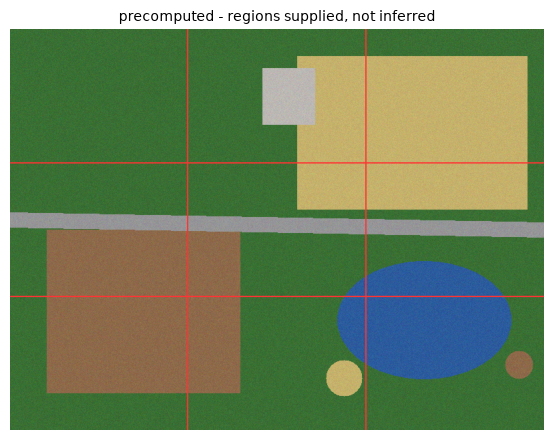


Guard: The 'precomputed' backend requires a `labels` array — typically a rasterised parcel or zoning layer.


In [5]:
import numpy as np

parcels = np.zeros(working.shape[:2], np.int32)
h, w = parcels.shape
for i in range(3):
    for j in range(3):
        parcels[i * h // 3:(i + 1) * h // 3, j * w // 3:(j + 1) * w // 3] = i * 3 + j + 1

r = tk.segmenters.segment(lab, "precomputed", labels=parcels)
print(r.describe())
display.show(tk.pipeline.render_segmentation_overlay(working, r.labels),
             "precomputed - regions supplied, not inferred", width=6)

try:
    tk.segmenters.segment(lab, "precomputed")
except ValueError as exc:
    print(f"\nGuard: {exc}")

## Choosing, in one line

Uniform region size is a virtue for a paintable template and a liability
for a parcel map. That is the whole heuristic — pick the backend whose
assumption about regions matches what you are going to do with them.